In [50]:
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from matplotlib import pyplot as plt
from sklearn.metrics import mean_absolute_error, r2_score,mean_squared_error
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
import joblib
import os


In [5]:
data=pd.read_csv(r"C:\Users\maira\OneDrive\Desktop\house_Price_Prediction\Data\Raw\HousePricePredictionIndore.csv")


In [6]:
data


,Location,Area,BHK,Floor,Balconies,Property Age,Parking,Near Market,Main Road,Furnishing,Price
0,Pipliyahana,2347,3,1,2,27,Yes,No,No,Non-Furnished,117.82
1,Mhow Road,1749,3,1,0,27,No,Yes,Yes,Semi-Furnished,65.28
2,Silicon City,4162,4,1,2,3,Yes,No,No,Furnished,170.25
3,Ring Road,4021,4,4,4,38,No,Yes,Yes,Non-Furnished,177.08
4,Palasia,2753,3,3,0,36,No,No,No,Non-Furnished,153.21
...,...,...,...,...,...,...,...,...,...,...,...
3795,MR-10,1540,3,3,1,16,Yes,No,No,Semi-Furnished,95.10
3796,Silicon City,1439,2,2,1,28,No,Yes,Yes,Semi-Furnished,44.99
3797,Vaishali Nagar,1766,3,4,3,16,No,No,No,Semi-Furnished,112.19
3798,Palasia,2697,3,1,1,14,No,No,No,Non-Furnished,177.10


In [7]:
data.head()

,Location,Area,BHK,Floor,Balconies,Property Age,Parking,Near Market,Main Road,Furnishing,Price
0,Pipliyahana,2347,3,1,2,27,Yes,No,No,Non-Furnished,117.82
1,Mhow Road,1749,3,1,0,27,No,Yes,Yes,Semi-Furnished,65.28
2,Silicon City,4162,4,1,2,3,Yes,No,No,Furnished,170.25
3,Ring Road,4021,4,4,4,38,No,Yes,Yes,Non-Furnished,177.08
4,Palasia,2753,3,3,0,36,No,No,No,Non-Furnished,153.21


In [8]:
data.shape


(3800, 11)

In [9]:
data.columns


Index(['Location', 'Area', 'BHK', 'Floor', 'Balconies', 'Property Age',
       'Parking', 'Near Market', 'Main Road', 'Furnishing', 'Price'],
      dtype='str')

In [10]:
data.info()


<class 'pandas.DataFrame'>
RangeIndex: 3800 entries, 0 to 3799
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Location      3800 non-null   str    
 1   Area          3800 non-null   int64  
 2   BHK           3800 non-null   int64  
 3   Floor         3800 non-null   int64  
 4   Balconies     3800 non-null   int64  
 5   Property Age  3800 non-null   int64  
 6   Parking       3800 non-null   str    
 7   Near Market   3800 non-null   str    
 8   Main Road     3800 non-null   str    
 9   Furnishing    3800 non-null   str    
 10  Price         3800 non-null   float64
dtypes: float64(1), int64(5), str(5)
memory usage: 326.7 KB


In [11]:
data.describe()

,Area,BHK,Floor,Balconies,Property Age,Price
count,3800.000000,3800.000000,3800.000000,3800.000000,3800.000000,3800.000000
mean,2702.470789,3.227895,2.435526,2.031316,22.560000,148.821232
std,1307.113477,1.022856,1.191375,1.408738,13.012278,93.282000
min,350.000000,1.000000,0.000000,0.000000,1.000000,16.790000
25%,1571.000000,3.000000,1.000000,1.000000,11.000000,78.185000
50%,2694.500000,3.000000,2.000000,2.000000,22.000000,131.860000
75%,3826.000000,4.000000,3.000000,3.000000,34.000000,197.315000
max,5000.000000,5.000000,4.000000,4.000000,45.000000,544.090000


In [12]:
data.isnull().sum()


Location        0
Area            0
BHK             0
Floor           0
Balconies       0
Property Age    0
Parking         0
Near Market     0
Main Road       0
Furnishing      0
Price           0
dtype: int64

In [13]:
data.describe()


,Area,BHK,Floor,Balconies,Property Age,Price
count,3800.000000,3800.000000,3800.000000,3800.000000,3800.000000,3800.000000
mean,2702.470789,3.227895,2.435526,2.031316,22.560000,148.821232
std,1307.113477,1.022856,1.191375,1.408738,13.012278,93.282000
min,350.000000,1.000000,0.000000,0.000000,1.000000,16.790000
25%,1571.000000,3.000000,1.000000,1.000000,11.000000,78.185000
50%,2694.500000,3.000000,2.000000,2.000000,22.000000,131.860000
75%,3826.000000,4.000000,3.000000,3.000000,34.000000,197.315000
max,5000.000000,5.000000,4.000000,4.000000,45.000000,544.090000


In [14]:
data.duplicated().sum()


np.int64(0)

In [15]:
data[data.duplicated()]


,Location,Area,BHK,Floor,Balconies,Property Age,Parking,Near Market,Main Road,Furnishing,Price


In [16]:
print("Total Duplicate Rows:", data.duplicated().sum())

Total Duplicate Rows: 0


In [17]:
data.dtypes


Location            str
Area              int64
BHK               int64
Floor             int64
Balconies         int64
Property Age      int64
Parking             str
Near Market         str
Main Road           str
Furnishing          str
Price           float64
dtype: object

In [18]:
data.describe()


,Area,BHK,Floor,Balconies,Property Age,Price
count,3800.000000,3800.000000,3800.000000,3800.000000,3800.000000,3800.000000
mean,2702.470789,3.227895,2.435526,2.031316,22.560000,148.821232
std,1307.113477,1.022856,1.191375,1.408738,13.012278,93.282000
min,350.000000,1.000000,0.000000,0.000000,1.000000,16.790000
25%,1571.000000,3.000000,1.000000,1.000000,11.000000,78.185000
50%,2694.500000,3.000000,2.000000,2.000000,22.000000,131.860000
75%,3826.000000,4.000000,3.000000,3.000000,34.000000,197.315000
max,5000.000000,5.000000,4.000000,4.000000,45.000000,544.090000


In [19]:
for col in data.select_dtypes(include=np.number).columns:
    print(col, (data[col] == 0).sum())

Area 0
BHK 0
Floor 131
Balconies 720
Property Age 0
Price 0


In [20]:
for col in data.select_dtypes(include=np.number).columns:
    print(col, (data[col] < 0).sum())

Area 0
BHK 0
Floor 0
Balconies 0
Property Age 0
Price 0


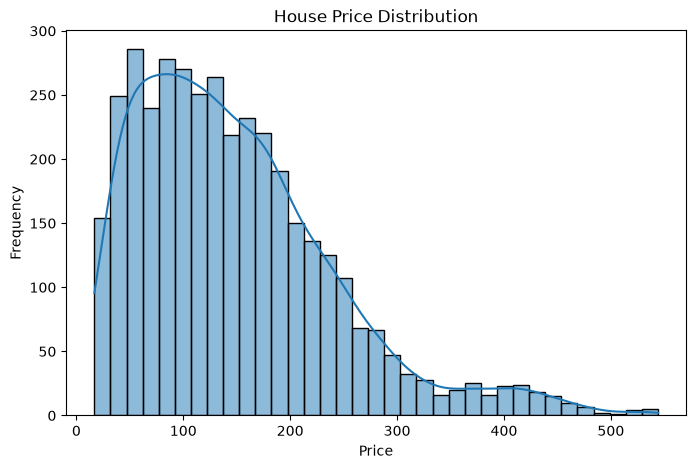

In [21]:
plt.figure(figsize=(8,5))

sns.histplot(data["Price"], kde=True)

plt.title("House Price Distribution")
plt.xlabel("Price")
plt.ylabel("Frequency")

plt.show()

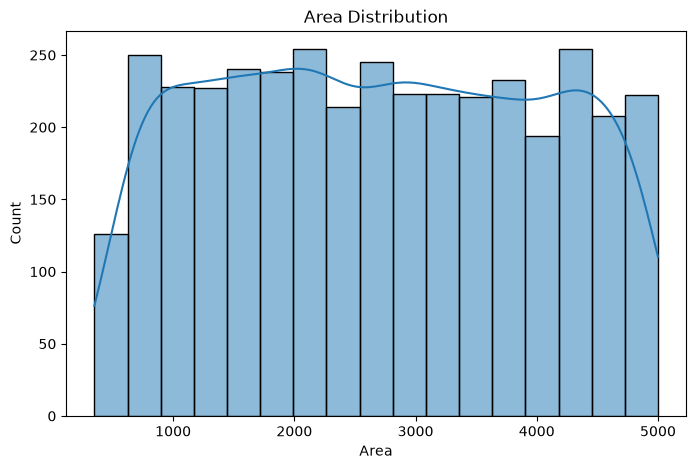

In [22]:
plt.figure(figsize=(8,5))

sns.histplot(data["Area"], kde=True)

plt.title("Area Distribution")

plt.show()

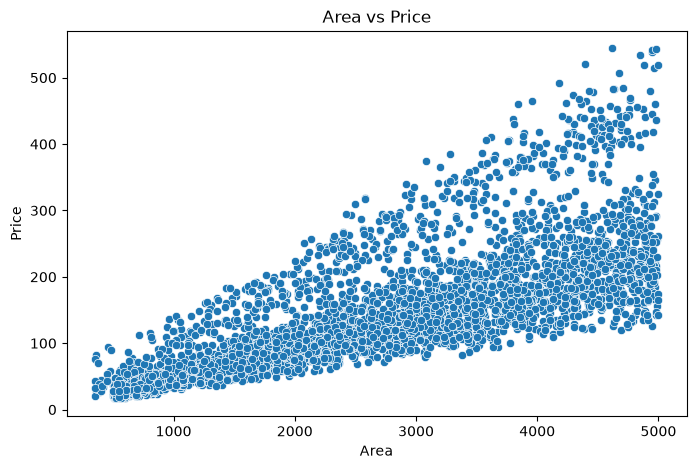

In [23]:
plt.figure(figsize=(8,5))

sns.scatterplot(data=data, x="Area", y="Price")

plt.title("Area vs Price")

plt.show()

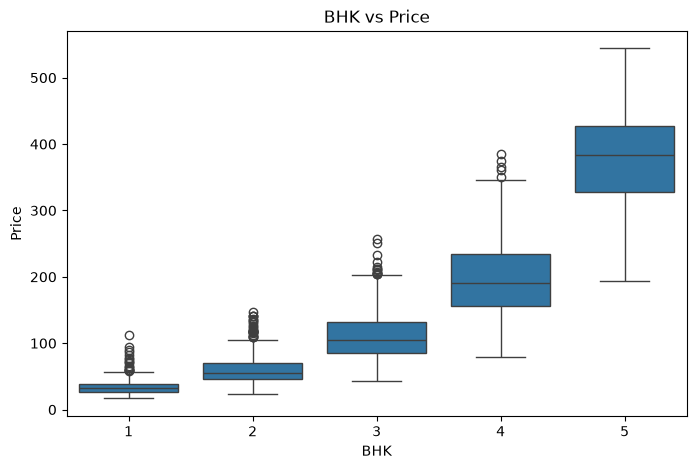

In [24]:
plt.figure(figsize=(8,5))

sns.boxplot(x='BHK', y='Price', data=data)

plt.title("BHK vs Price")

plt.show()

In [25]:
location_price = data.groupby('Location')['Price'].mean().sort_values(ascending=False)

print(location_price)

Location
Scheme No. 54         302.8295
Vijay Nagar           278.7640
Super Corridor        275.5526
Bengali Square        238.6941
Mahalaxmi Nagar       225.4482
Nipania               205.5632
Palasia               187.1082
Vaishali Nagar        174.0671
AB Road               163.4159
Rau                   163.4009
Scheme No. 140        157.3123
Tilak Nagar           154.9724
MR-10                 149.8662
Pipliyahana           142.6805
Indore Bypass         142.2007
Ring Road             141.8171
Navlakha              140.8387
LIG Colony            139.0081
Annapurna Road        136.9036
Saket Nagar           133.1308
Bhawarkuan            128.3008
Mahu Naka             125.7679
Lokmanya Nagar        125.1646
Scheme No. 94         124.4391
Gandhi Nagar          120.1122
Rajendra Nagar        119.2581
Khandwa Road          118.5690
CAT Road              116.5627
Sudama Nagar          116.2348
Pardesipura           115.8225
Limbodi               107.3809
Khajrana              102.1055

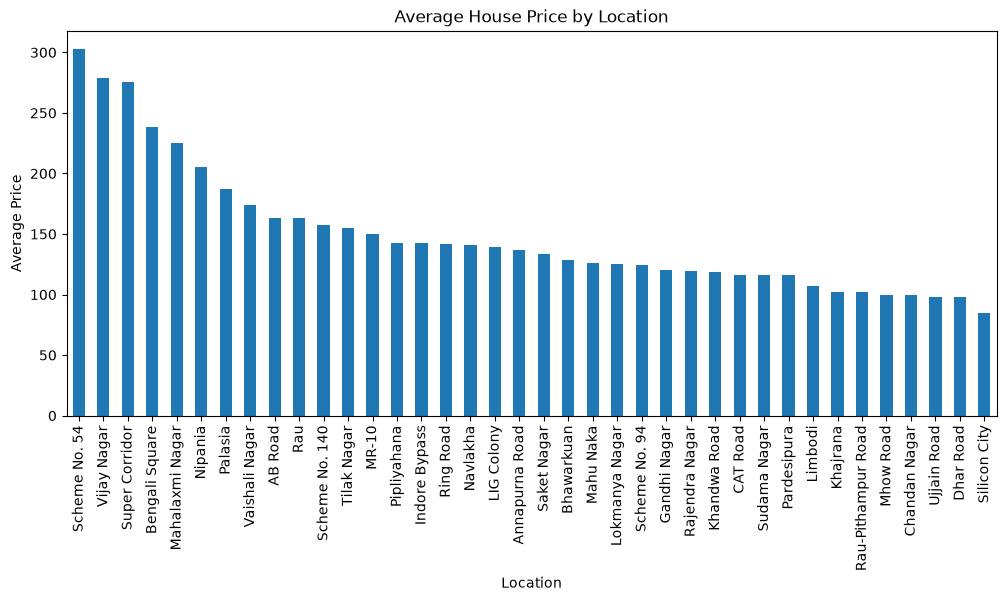

In [26]:
location_price.plot(kind='bar', figsize=(12,5))

plt.title("Average House Price by Location")
plt.ylabel("Average Price")

plt.show()

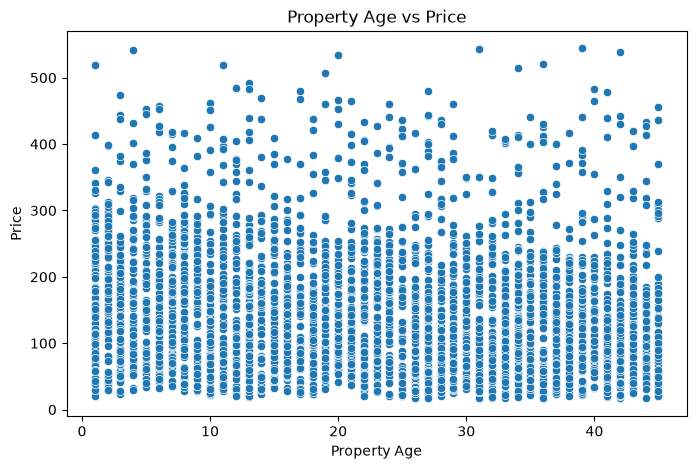

In [27]:
plt.figure(figsize=(8,5))

sns.scatterplot(x='Property Age', y='Price', data=data)

plt.title("Property Age vs Price")

plt.show()

In [28]:
X = data.drop('Price', axis=1)
y = data['Price']

In [29]:
num_cols = [
    'Area',
    'BHK',
    'Floor',
    'Balconies',
    'Property Age'
]

cat_cols = [
    'Location',
    'Parking',
    'Near Market',
    'Main Road',
    'Furnishing'
]

In [30]:

X_train, X_test, y_train, y_test = train_test_split( X,y,test_size=0.2,random_state=42)

In [31]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (3040, 10)
X_test: (760, 10)
y_train: (3040,)
y_test: (760,)


In [32]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
    ]
)


model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

In [33]:
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['Location','Area','BHK',...,'Near Market','Main Road','Furnishing']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of column

In [34]:
y_pred = model.predict(X_test)

print(y_pred[:10])

[ 34.74016812 212.7953107  239.746756    99.89246074 372.1621575
 217.31754201  37.48037028 238.9791539  -15.06254008 169.42146852]


In [35]:
comparison = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred
})

comparison.head(10)

,Actual Price,Predicted Price
0,43.01,34.740168
1,196.08,212.795311
2,231.09,239.746756
3,94.77,99.892461
4,395.47,372.162158
5,225.54,217.317542
6,59.88,37.480370
7,225.09,238.979154
8,27.34,-15.062540
9,149.21,169.421469


In [36]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 18.082796762241053
MSE: 697.880549523489
RMSE: 26.417428896913663
R2 Score: 0.9218760729256826


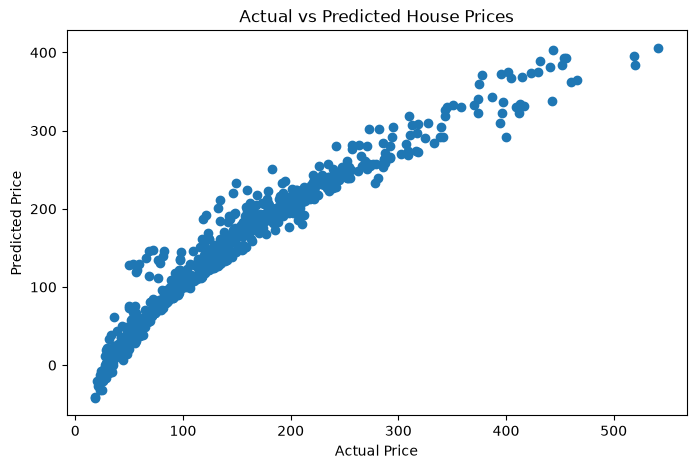

In [37]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted House Prices")

plt.show()

In [38]:
residuals = y_test - y_pred

print(residuals.head())

1003     8.269832
594    -16.715311
461     -8.656756
3018    -5.122461
3091    23.307842
Name: Price, dtype: float64


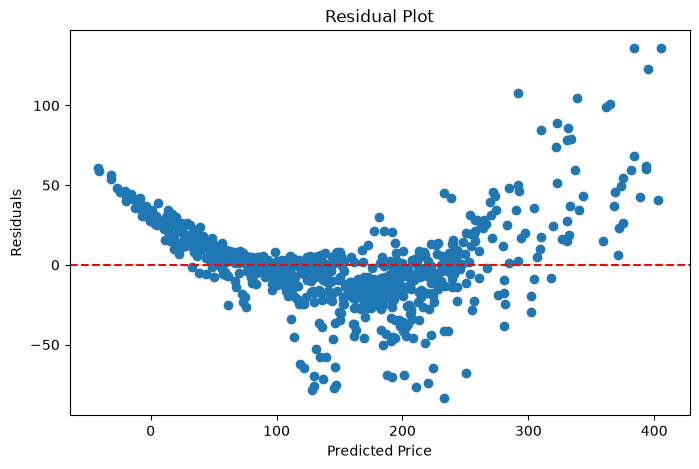

In [39]:
plt.figure(figsize=(8, 5))

plt.scatter(y_pred, residuals)

plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel("Predicted Price")
plt.ylabel("Residuals")
plt.title("Residual Plot")

plt.show()

In [47]:
joblib.dump(model, 'linear_regression_model.pkl')

['linear_regression_model.pkl']

In [41]:
loaded_model = joblib.load('linear_regression_model.pkl')

print("Model Loaded Successfully!")

Model Loaded Successfully!


In [42]:
new_house = pd.DataFrame({
    'Location': ['Vijay Nagar'],
    'Area': [2000],
    'BHK': [3],
    'Floor': [2],
    'Balconies': [2],
    'Property Age': [5],
    'Parking': ['Yes'],
    'Near Market': ['Yes'],
    'Main Road': ['Yes'],
    'Furnishing': ['Semi-Furnished']
})

loaded_model = joblib.load('linear_regression_model.pkl')

predicted_price = loaded_model.predict(new_house)

print("Predicted House Price:", predicted_price[0])

Predicted House Price: 252.40493220781832


In [43]:
import os

print(os.path.exists('linear_regression_model.pkl'))

True


In [44]:
test_prediction = loaded_model.predict(X_test)

print(test_prediction[:10])

[ 34.74016812 212.7953107  239.746756    99.89246074 372.1621575
 217.31754201  37.48037028 238.9791539  -15.06254008 169.42146852]


In [45]:
print(np.allclose(y_pred, test_prediction))

True


In [48]:
joblib.dump(model, '../Models/linear_regression_model.pkl')

['../Models/linear_regression_model.pkl']

In [49]:
print(data['Price'].describe())
print(data['Price'].head(10))

count    3800.000000
mean      148.821232
std        93.282000
min        16.790000
25%        78.185000
50%       131.860000
75%       197.315000
max       544.090000
Name: Price, dtype: float64
0    117.82
1     65.28
2    170.25
3    177.08
4    153.21
5    239.37
6     98.41
7     80.09
8    107.87
9     60.56
Name: Price, dtype: float64
